<a href="https://colab.research.google.com/github/negativespace-exe/Econometrics-Work/blob/main/ECON_6550_Assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Applying the difference-in-differences regression,

\begin{equation}
y_{it} = \beta_0 + \beta_1TreatmentGroup_i + \beta_2PostTreatment_t + (\beta_{DiD}TreatmentGroup_i * PostTreatment_t) + \epsilon_{it}
\end{equation}

on a sample of just Utah and Colorado, where $y_{it}$ is the crime rate, and treatment is recreational marijuana legalization, which gives
\begin{equation}
\beta_{DiD} = TS^* = CS^*
\end{equation}

Noting meaning of parameters:

* $\beta_0$ = the average crime rate in Utah before Colorado legalized
marijuana

* $\beta_0 + \beta_1$ = average crime rate in Colorado before Colorado legalized marijuana

* $\beta_2$ = change in average crime rate in Utah after Colorado legalized marijuana

* $\beta_{DiD}$ = how much more average crime rate in Colorado changed compared to how Utah changed after Colorado legalized marijuana

* $\beta_2 + \beta_{DiD}$ = how much Colorado's average crime rate changed after legalizing marijuana

 Subtracting change in control group from change in treatement group:

 \begin{equation}
 DiD = (\beta_2 + \beta_{DiD}) - \beta_2
 \\
 DiD = \beta_{DiD}
 \\
 \end{equation}

$TS^*$ = Time-Series Estimator = (Colorado after - before) - (Utah after - before)

$CS^*$ = Cross-Sectional Estimator = (Colorado before - Utah before) - (Colorado after - Utah after)

\begin{equation}
TS^* = ((\beta_0 + \beta_1 + \beta_2 + \beta_{DiD}) - (\beta_0 + \beta_1))
-
((\beta_0 + \beta_2) - (\beta_0))
\\
\end{equation}

\begin{equation}
TS^* = (\beta_2 + \beta_{DiD})
-
(\beta_2)
\\
\end{equation}

\begin{equation}
TS^* = \beta_{DiD}
\\
\end{equation}

\begin{equation}
CS^* = ((\beta_0 + \beta_1) - (\beta_0))
-
((\beta_0 + \beta_1 + \beta_2 + \beta_{DiD}) - (\beta_0 + \beta_2))
\\
\end{equation}

\begin{equation}
CS^* = (\beta_1)
-
(\beta_1 + \beta_{DiD})
\\
\end{equation}

\begin{equation}
CS^* = \beta_{DiD}
\\
\end{equation}

So:
\begin{equation}
TS^* = CS^* = \beta_{DiD}
\end{equation}


 Simulated data associated with example:

**Just an explanation of what follows:** I realized after I created the simulation below that it was modeling a different situation, one where the treatment effect actually grows as a function of time, which isn't what happens in the regression we were working with above. I left it just because it was interesting to me to do and understand, but I then afterwards created the plot that better reflects the above regression model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

In [2]:
beta_0 = 5
beta_1 = 10
treatment = 20

# Define the Utah trend as a function of time
def Utah_curve(time):
    return 0.5 * time + beta_0

# Define Colorado counterfactual (assuming parallel trend) also function of time
def Colorado_counterfactual(time):
    return 0.5 * time + (beta_0 + beta_1)

# Define Colorado treatment effect
def Colorado_treatment(time):
    return 1.2 * (time - treatment) + Colorado_counterfactual(treatment)

# Getting y-value of Colorado_treatement at time = treatment
y_Colorado_treatment = Colorado_treatment(treatment)

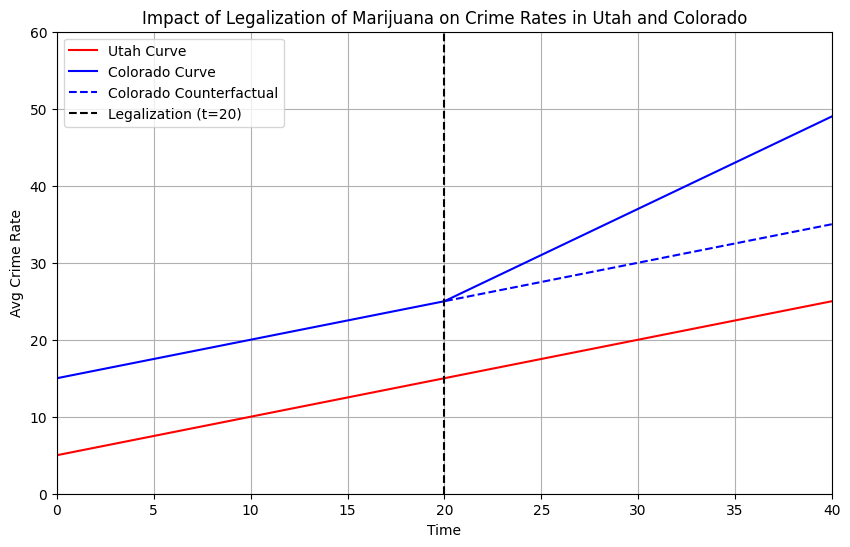

In [3]:
#plotting

# Set the range for time
time = np.linspace(0, 40, 500)

# Calculate the curves
Utah_crime = Utah_curve(time)
Colorado_counterfactual_crime = Colorado_counterfactual(time)
Colorado_crime = Colorado_treatment(time)



# Create the plot
plt.figure(figsize=(10, 6))

# Plot Utah_crime
plt.plot(time, Utah_crime, color='red', label='Utah Curve')

# Colorado before legalization
plt.plot(
    time[time < treatment],
    Colorado_counterfactual_crime[time < treatment],
    color='blue'

)

# Colorado after legalization
plt.plot(
    time[time >= treatment],
    Colorado_crime[time >= treatment],
    color='blue',
    label='Colorado Curve'
)

# Counterfactual after legalization
plt.plot(
    time[time >= treatment],
    Colorado_counterfactual_crime[time >= treatment],
    color='blue',
    linestyle='dashed',
    label='Colorado Counterfactual'
)

# Plot treatment line
plt.axvline(
    x=treatment,
    color='black',
    linestyle='dashed',
    label=f'Legalization (t={treatment})'
)

# Add labels and title
plt.xlabel('Time')
plt.ylabel('Avg Crime Rate')
plt.title('Impact of Legalization of Marijuana on Crime Rates in Utah and Colorado')


# Set axis limits
plt.xlim(0, 40)
plt.ylim(0, 60)

# Show grid
plt.grid(True)

# Add legend
plt.legend()

# Show the plot
plt.show()


Here is the model that treats time as a categorical variable and is more in line with the regression we were working with earlier.

In [4]:
beta_0 = 5
beta_1 = 10
beta_2 = 5
beta_DiD = 7
treatment = 20

def Utah_curve(time):
    return beta_0 + beta_2 * (time >= treatment)

def Colorado_counterfactual(time):
    return beta_0 + beta_1 + beta_2 * (time >= treatment)

def Colorado_treatment(time):
    return Colorado_counterfactual(time) + beta_DiD

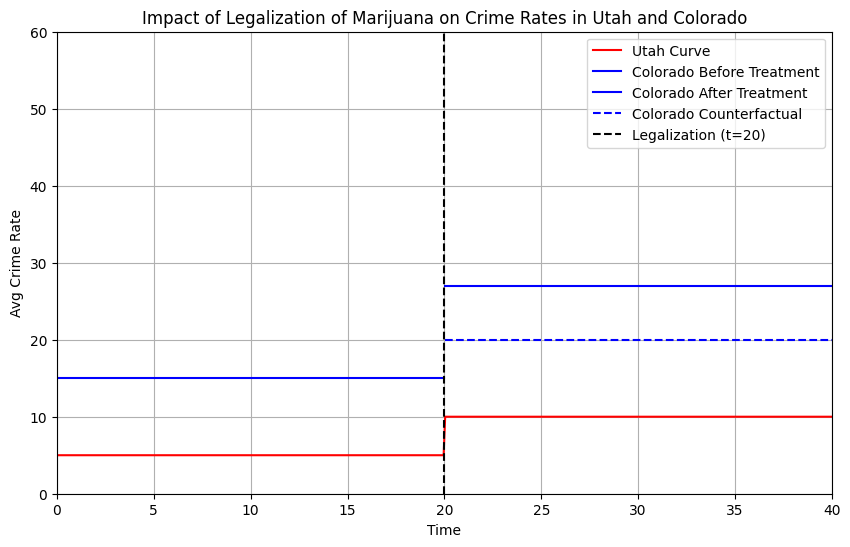

In [5]:
#plotting

# Set the range for time
time = np.linspace(0, 40, 500)

# Calculate the curves
Utah_crime = Utah_curve(time)
Colorado_counterfactual_crime = Colorado_counterfactual(time)
Colorado_crime = Colorado_treatment(time)



# Create the plot
plt.figure(figsize=(10, 6))

# Plot Utah_crime
plt.plot(time, Utah_crime, color='red', label='Utah Curve')

# Colorado before legalization
plt.plot(
    time[time < treatment],
    Colorado_counterfactual_crime[time < treatment],
    color='blue',
    label='Colorado Before Treatment'
)

# Colorado after legalization
plt.plot(
    time[time >= treatment],
    Colorado_crime[time >= treatment],
    color='blue',
    label='Colorado After Treatment'
)

# Counterfactual after legalization
plt.plot(
    time[time >= treatment],
    Colorado_counterfactual_crime[time >= treatment],
    color='blue',
    linestyle='dashed',
    label='Colorado Counterfactual'
)

# Plot treatment line
plt.axvline(
    x=treatment,
    color='black',
    linestyle='dashed',
    label=f'Legalization (t={treatment})'
)

# Add labels and title
plt.xlabel('Time')
plt.ylabel('Avg Crime Rate')
plt.title('Impact of Legalization of Marijuana on Crime Rates in Utah and Colorado')


# Set axis limits
plt.xlim(0, 40)
plt.ylim(0, 60)

# Show grid
plt.grid(True)

# Add legend
plt.legend()

# Show the plot
plt.show()


##Comparing the outcomes of a 2SLS model with a Two-Stage Machine Learning model

An example of a simultaneous and endogenous system might be:



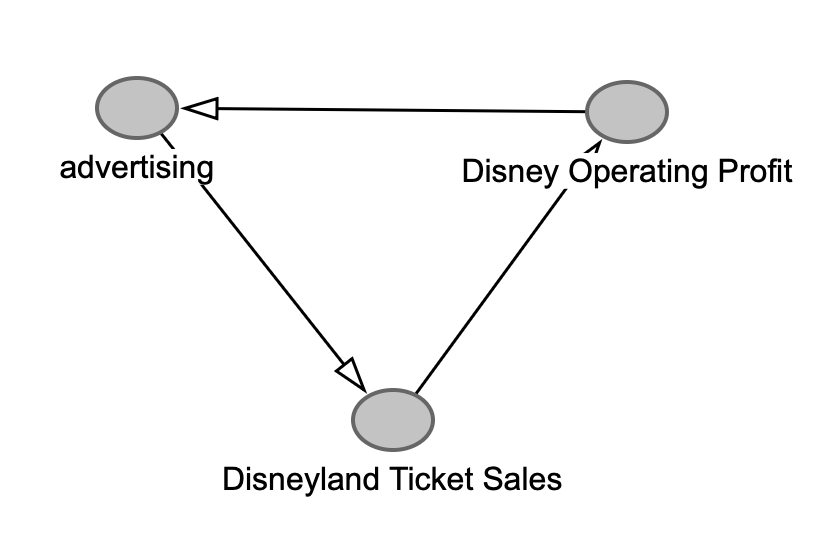

Essentially:
1. More Disneyland ticket sales increase profits
2. Higher profits allow Disney to allocate more money to advertising
3. Advertising attracts visitors and increases Disneyland ticket sales


**Ticket sales** could be modeled with the following regression:

\begin{equation}
Sales = \alpha_0 + \alpha_1Advertising + \alpha_2TicketPrice + \epsilon_S
\end{equation}

**Operating Profit** might be:

\begin{equation}
Profit = \beta_0 + \beta_1Sales + \beta_2OperatingCosts + \epsilon_P
\end{equation}

And **advertising** could be described by:

\begin{equation}
Advertising = \gamma_0 + \gamma_1Profit + \epsilon_A
\end{equation}

We might want to find out what the effect of advertising is on ticket sales.

To try to define $Sales$ without directly using $Advertising$ and $Profit$, we can start by substituting the Advertising equation into the Sales regression:

\begin{equation}
Sales = \alpha_0 + \alpha_1(\gamma_0 + \gamma_1Profit + \epsilon_A) + \alpha_2TicketPrice + \epsilon_S
\end{equation}

And then when we replace Profit with its respective regression, we end up with:

\begin{equation}
Sales = \alpha_0 + \alpha_1(\gamma_0 + \gamma_1(\beta_0 + \beta_1Sales + \beta_2OperatingCosts + \epsilon_P) + \epsilon_A) + \alpha_2TicketPrice + \epsilon_S
\end{equation}


Solving for $Sales$, we get:

\begin{equation}
Sales = \alpha_0 + \alpha_1\gamma_0 + \alpha_1\gamma_1(\beta_0 + \beta_1Sales + \beta_2OperatingCosts + \epsilon_P) + \alpha_1\epsilon_A + \alpha_2TicketPrice + \epsilon_S
\end{equation}

\begin{equation}
Sales = \alpha_0 + \alpha_1\gamma_0 + \alpha_1\gamma_1\beta_0 + \alpha_1\gamma_1\beta_1Sales + \alpha_1\gamma_1\beta_2OperatingCosts + \alpha_1\gamma_1\epsilon_P + \alpha_1\epsilon_A + \alpha_2TicketPrice + \epsilon_S
\end{equation}

\begin{equation}
Sales - \alpha_1\gamma_1\beta_1Sales = \alpha_0 + \alpha_1\gamma_0 + \alpha_1\gamma_1\beta_0  + \alpha_1\gamma_1\beta_2OperatingCosts + \alpha_1\gamma_1\epsilon_P + \alpha_1\epsilon_A + \alpha_2TicketPrice + \epsilon_S
\end{equation}

\begin{equation}
Sales(1 - \alpha_1\gamma_1\beta_1) = \alpha_0 + \alpha_1\gamma_0 + \alpha_1\gamma_1\beta_0  + \alpha_1\gamma_1\beta_2OperatingCosts + \alpha_1\gamma_1\epsilon_P + \alpha_1\epsilon_A + \alpha_2TicketPrice + \epsilon_S
\end{equation}


\begin{equation}
Sales = \frac{\alpha_0 + \alpha_1\gamma_0 + \alpha_1\gamma_1\beta_0  + \alpha_1\gamma_1\beta_2OperatingCosts + \alpha_1\gamma_1\epsilon_P + \alpha_1\epsilon_A + \alpha_2TicketPrice + \epsilon_S}{(1 - \alpha_1\gamma_1\beta_1)}
\end{equation}


\begin{equation}
Sales = \frac{\alpha_0 + \alpha_1(\gamma_0 + \gamma_1(\beta_0  + \beta_2OperatingCosts + \epsilon_P) + \epsilon_A) + \alpha_2TicketPrice + \epsilon_S}{(1 - \alpha_1\gamma_1\beta_1)}
\end{equation}

This expresses $Sales$ in terms of the exogenous variables $OperatingCosts$ and $TicketPrice$ (with error terms). The new equation doesn't contain endogenous explanatory variables anymore, but it is still based on the relationships from the original system. Because advertising affects ticket sales, and ticket sales affect profit, and profit affects advertising, advertising stays endogenous in the original $Sales$ regression.


If we run OLS on this system with simulated data, we get:

In [6]:
#### Parameters for simulation ####
np.random.seed(42)
n = 5000

# Equation 1 – Disneyland Ticket Sales (Daily)
alpha0 = 15000       # Intercept (baseline number of tickets sold)
alpha1 = 0.1         # Effect of Advertising (paremeter of interest)
alpha2 = -50         # Effect of Ticket Price

# Equation 2 – Operational Profit (Daily)
beta0 = -100000     # Intercept (baseline park expenses)
beta1 = 250         # profit per ticket sold
beta2 = -1           # Daily Operating Costs

# Equation 3 – Advertising
gamma0 = 10000      # Baseline advertising spending
gamma1 = 0.02       # Effect of OperationalProfit on Advertising

# Generate exogenous variables and error terms (created outside the system)
ticket_price = np.random.normal(150, 20, n)            # Ticket Price (exogenous)
operating_cost = np.random.normal(500000, 75000, n)    # Operating Costs (exogenous)

# Error terms
epsilon_s = np.random.normal(0, 1000, n)    # sales error
epsilon_p = np.random.normal(0, 100000, n)     # profit error
epsilon_a = np.random.normal(0, 3000, n)       # advertising error

# Generate sales using exogenous variables and error terms
sales = (
    alpha0 + alpha1*(gamma0 + gamma1*(beta0 + beta2*operating_cost
    + epsilon_p) + epsilon_a) + alpha2*ticket_price + epsilon_s) / (1 - alpha1*gamma1*beta1)

# Generate endogenous independent variables
profit =  beta0 + beta1*sales + beta2*operating_cost + epsilon_p
advertising = gamma0 + gamma1*profit + epsilon_a

# Run OLS on Equation (1) and examine the advertising coefficient
X_ols = sm.add_constant(np.column_stack([advertising, ticket_price]))  # Regressors: advertising, ticket_price
ols_model = sm.OLS(sales, X_ols).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                 5.680e+04
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:04:24   Log-Likelihood:                -39092.
No. Observations:                5000   AIC:                         7.819e+04
Df Residuals:                    4997   BIC:                         7.821e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       5944.9691    116.559     51.004      0.0

The advertising coefficient (x1) is 0.1626 while the true value is 0.1. That's a pretty significant overestimation of the causal effect. Interestingly, the adjusted R2 value is really, really high, but we know that the advertising coefficient is really biased. So we could potentially misunderstand the causality of this system if we accepted this model.

In [7]:
#calculating correlation between Advertising and the Sales error term
np.corrcoef(advertising, epsilon_s)[0, 1]

np.float64(0.6333434365011597)

The correlation is indeed pretty high!

We can take advantage of the exogeneity of $OperatingCosts$ try to address the endogeneity with a 2SLS model by estimating $Advertising$ from $OperatingCosts$ and using $TicketPrice$ as a control:

\begin{equation}
Advertising = \pi_0 + \pi_1OperatingCosts + \pi_2TicketPrice + u
\end{equation}

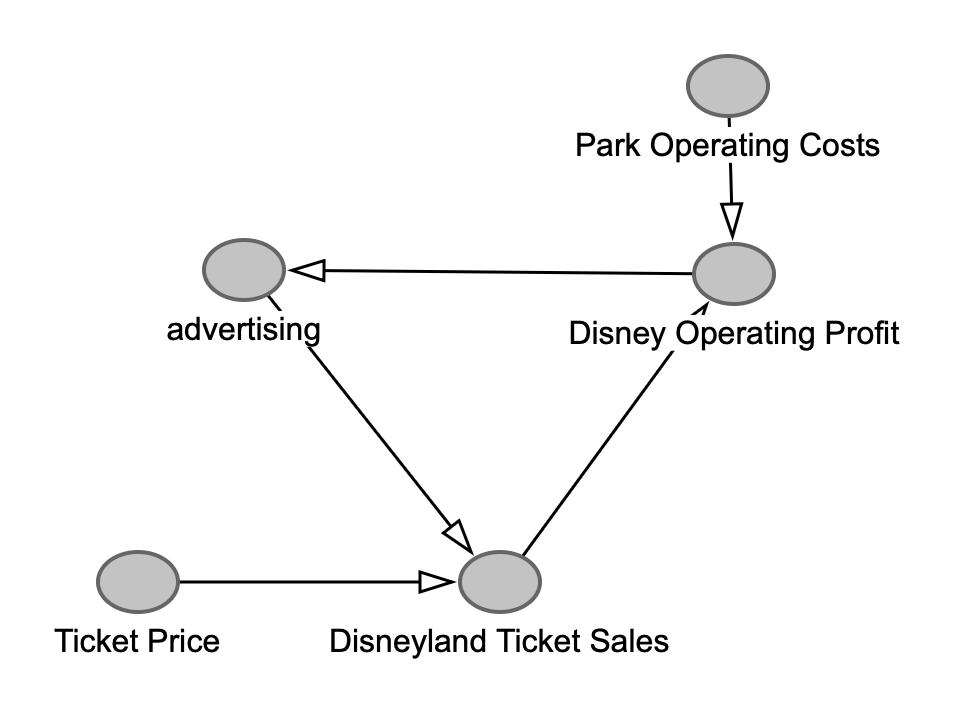

In [8]:
# 2SLS using operating_cost as the instrument for advertising (ticket_price acting as an exogenous control here)

# First stage: predict advertising from instrument(s) + control(s)
X_operating_cost = sm.add_constant(np.column_stack([operating_cost, ticket_price]))
ols_advertising_model = sm.OLS(advertising, X_operating_cost).fit()

# Get fitted values of advertising from the first stage
fitted_advertising = ols_advertising_model.fittedvalues

# Second stage: regress sales on ticket_price + fitted advertising
X_sales = sm.add_constant(np.column_stack([ticket_price, fitted_advertising]))
ols_sales_model = sm.OLS(sales, X_sales).fit()

# Print summaries for both stages
print("First stage OLS: advertising ~ 1 + operating_cost + ticket_price")
print(ols_advertising_model.summary())

print("\nSecond stage OLS (2SLS step 2): sales ~ 1 + ticket_price + fitted_advertising")
print(ols_sales_model.summary())

#comparing with true advertising coefficient
print()
print(f"True advertising effect: {alpha1:.4f}")
print(f"OLS advertising estimate: {ols_model.params[1]:.4f}")
print(f"2SLS advertising estimate: {ols_sales_model.params[2]:.4f}")

First stage OLS: advertising ~ 1 + operating_cost + ticket_price
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.413
Model:                            OLS   Adj. R-squared:                  0.413
Method:                 Least Squares   F-statistic:                     1756.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:04:54   Log-Likelihood:                -54197.
No. Observations:                5000   AIC:                         1.084e+05
Df Residuals:                    4997   BIC:                         1.084e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

The 2SLS model did a much better job of estimating the true coefficients than the OLS estimate. The $Advertising$ coefficient was 0.1 and 2SLS was able to get quite close with an estimate of 0.1018, which is a much better result than the OLS estimate of 0.1626.

It also did a much better job estimating $TicketPrice$ and the intercept as well!
* True Intercept: 15000, OLS estimate: 5944.97, 2SLS estimate: 14770
* True ticket_price coefficient: -50, OLS estimate: -19.22, 2SLS estimate: -49.24

The instrument seems to have done really well as an estimator for $Advertising$! It seems to have been quite relevant (it had a F statistic of 330.4 in the first stage), and is also exogenous because the instrument $OperatingCost$ was uncorrelated with the error term affecting $Sales$.

Plotting the results:

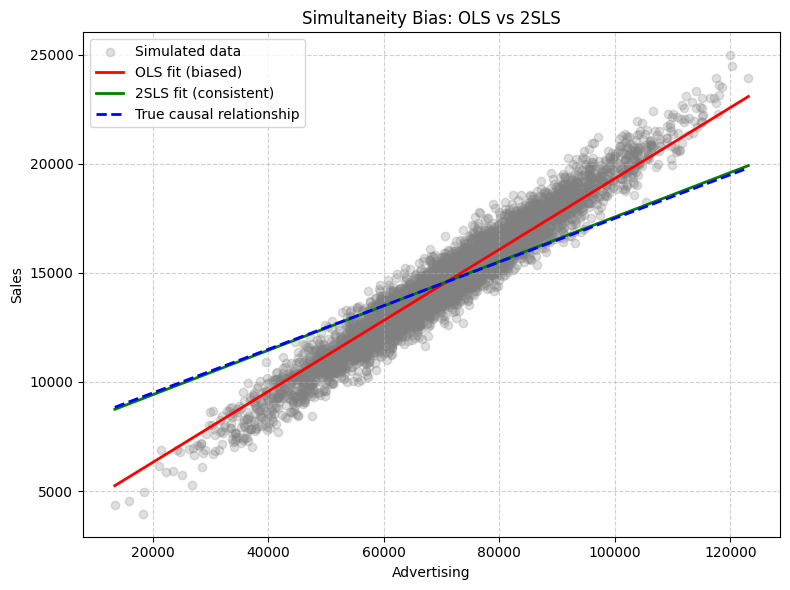

In [9]:
# --- Hold ticket_price constant (e.g., at the mean) ---
ticket_price_mean = np.mean(ticket_price)

# --- Create a reasonable range of advertising costs based on the data ---
x_min, x_max = advertising.min(), advertising.max()
x_grid = np.linspace(x_min, x_max, 200)

# --- Predicted sales using OLS coefficients ---
b0, b_adv, b_ticket_price  = ols_model.params
yhat_ols = b0 + b_ticket_price * ticket_price_mean + b_adv * x_grid

# --- Predicted sales using 2SLS coefficients ---
b0_iv, b_ticket_price_iv, b_adv_iv = ols_sales_model.params
yhat_iv = b0_iv + b_ticket_price_iv * ticket_price_mean + b_adv_iv * x_grid

# --- True values
yhat_true = alpha0 + alpha1 * x_grid + alpha2 * ticket_price_mean


# --- Plot OLS and 2SLS fits over the simulated data ---
plt.figure(figsize=(8, 6))
plt.scatter(advertising, sales, alpha=0.25, color="gray", label="Simulated data")
plt.plot(x_grid, yhat_ols, color="red", linewidth=2, label="OLS fit (biased)")
plt.plot(x_grid, yhat_iv, color="green", linewidth=2, label="2SLS fit (consistent)")
plt.plot(x_grid, yhat_true,color="blue",linewidth=2,linestyle="--",label="True causal relationship")
plt.xlabel("Advertising")
plt.ylabel("Sales")
plt.title("Simultaneity Bias: OLS vs 2SLS")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Now I'll try using a 2 Stage Machine Learning model.



In [10]:
# First-stage model: Random Forest
rf = RandomForestRegressor(
    n_estimators=400,      # number of trees in the forest (higher = smoother average)
    random_state=42,       # ensures reproducibility (so results don't change each run)
    min_samples_leaf=5,    # prevents overfitting by forcing each leaf to have ≥5 observations
    n_jobs=-1              # use all available CPU cores to run faster
)

# 2-fold cross-fitting setup
n = len(sales)
idx = np.arange(n)
np.random.shuffle(idx)     # randomize order of observations
fold_A = idx[: n//2]       # first half of data (Fold A)
fold_B = idx[n//2 :]       # second half (Fold B)

# features for first stage: instrument(s) + control(s)
X_features = np.column_stack([operating_cost, ticket_price])

# training on A, predicting for B (out-of-sample) ---
rf.fit(X_features[fold_A], advertising[fold_A])
advertising_hat_B = rf.predict(X_features[fold_B])

# training on B, predicting for A (out-of-sample) ---
rf.fit(X_features[fold_B], advertising[fold_B])
advertising_hat_A = rf.predict(X_features[fold_A])

# combining out-of-fold predictions
advertising_hat_cf = np.empty_like(advertising, dtype=float)
advertising_hat_cf[fold_A] = advertising_hat_A
advertising_hat_cf[fold_B] = advertising_hat_B

# First-stage fit check
first_stage_r2 = r2_score(advertising, advertising_hat_cf)
# This R² is calculated using only out-of-sample predictions,
# so it reflects the instrument’s predictive strength *without* overfitting.

# Second-stage regression
# Regress sales on ticket_price and the instrumented advertising
X_second_stage = sm.add_constant(np.column_stack([ticket_price, advertising_hat_cf]))
sml_model = sm.OLS(sales, X_second_stage).fit(cov_type="HC1")
# HC1 = heteroskedasticity-consistent robust standard errors

# --- 5) Print results for classroom discussion ---
print("=== Two-Stage Machine Learning (2SML, Random Forest, 2-fold cross-fitting) ===")
print(f"Coefficient on instrumented advertising: {sml_model.params[-1]:.4f}")
print(f"Robust SE (HC1): {sml_model.bse[-1]:.4f}")
print(f"First-stage out-of-sample R^2: {first_stage_r2:.3f}")

=== Two-Stage Machine Learning (2SML, Random Forest, 2-fold cross-fitting) ===
Coefficient on instrumented advertising: 0.0385
Robust SE (HC1): 0.0064
First-stage out-of-sample R^2: 0.357


In [11]:
#creating dataframe of all results to compare
comparison = pd.DataFrame({
    "Model": ["True", "OLS", "2SLS", "Random Forest 2SML"],
    "Advertising coefficient": [
        alpha1,
        ols_model.params[1],
        ols_sales_model.params[2],
        sml_model.params[2]
    ]
})

comparison["Absolute error"] = abs(comparison["Advertising coefficient"] - alpha1)

print(comparison)

                Model  Advertising coefficient  Absolute error
0                True                 0.100000        0.000000
1                 OLS                 0.162581        0.062581
2                2SLS                 0.101825        0.001825
3  Random Forest 2SML                 0.038485        0.061515


Wow, it's interesting that the RF 2SML was much worse than the 2SLS model at estimating the $Advertising$ coefficient! It did have a similar absolute error to the OLS estimator though, and its estimate of the $Advertising$ coefficient is about as far off in the opposite direction as the OLS estimate. I'm curious about the standard deviations of each model as compared to the true values:

In [12]:
print("Actual advertising SD:", np.std(advertising))
print("Linear fitted advertising SD:", np.std(fitted_advertising))
print("RF fitted advertising SD:", np.std(advertising_hat_cf))

print(
    "Correlation between linear and RF predictions:",
    np.corrcoef(fitted_advertising, advertising_hat_cf)[0, 1]
)

Actual advertising SD: 16099.773556635471
Linear fitted advertising SD: 10343.447212505353
RF fitted advertising SD: 10884.979362795902
Correlation between linear and RF predictions: 0.9423367545028026


So it seems like both models are actually seeing different patterns, despite the coefficient estimates being different.

The difference must come down to how the RF model is implementing its predictions into the second stage regression. I'm going to try using the stage one RF predictions as an instrumnet, rather than just substituting them into the Sales equation for stage two.

In [13]:
# Residualize sales, advertising, and RF predictions on ticket_price
X_control = sm.add_constant(ticket_price)

sales_resid = sm.OLS(sales, X_control).fit().resid
advertising_resid = sm.OLS(advertising, X_control).fit().resid
rf_resid = sm.OLS(advertising_hat_cf, X_control).fit().resid

# IV coefficient using RF predictions as the instrument
iv_rf_coef = (
    np.dot(rf_resid, sales_resid)
    / np.dot(rf_resid, advertising_resid)
)

print(f"True coefficient: {alpha1:.4f}")
print(f"Linear 2SLS coefficient: {ols_sales_model.params[2]:.4f}")
print(f"RF plug-in coefficient: {sml_model.params[2]:.4f}")
print(f"RF-based IV coefficient: {iv_rf_coef:.4f}")

True coefficient: 0.1000
Linear 2SLS coefficient: 0.1018
RF plug-in coefficient: 0.0385
RF-based IV coefficient: 0.0961


Hmmm! So if we just substitute the RF predictions right into the second stage regression, we get a coefficient estimate that is pretty far off. But if we use the predictions as an instrument for actual advertising, then we get something much closer to the real value.

After doing some research, this seems to be because OLS type predictions and RF predictions work differently, mathematically. In my case, the OLS model made sure that the fitted Advertising values and the error $u$ had a covariance of 0.

But RFs don't do that, and that makes a difference because when we use the predictions in the second stage equation, the error $u$ gets added to the error of the Sales equation, which is an issue because for OLS to work correctly, $\hat{Advertising}$ needs to be uncorrelated with that new combined error term. This seems to be what ends up distorting the $Advertising$ coefficient. But if we use the RF predictions as an instrument for actual advertising, then we don't need those predictions to be orthogonal to their own prediction errors (to have a covariance of 0). We just use them to estimate the effect of actual advertising on sales that they identify.